<a href="https://colab.research.google.com/github/saopa28/INSE-6450/blob/main/Milestone%203/Milestone2_Feedback.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Setup and Configuration

In [1]:
import os, gc, sys, json, time, subprocess, numpy as np, pandas as pd, xgboost as xgb, psutil
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
pd.set_option("display.float_format", "{:.6f}".format)

DATA_PATH = "https://github.com/saopa28/INSE-6450/releases/download/v1.0-engineered/criteo_uplift_engineered.zip"
TARGET = "conversion"
SPLIT_SEED = 42                         # split fixed across all runs (same as Milestone 2)
MODEL_SEEDS = [42, 1, 2]                # multi-seed: model randomness (subsample / colsample)
TUNE_ROWS = 3_000_000                   # tuning uses a fixed train subsample to bound Colab time; final fits use all train rows
OUT = "/content/m2_improvements"; os.makedirs(OUT, exist_ok=True)

RAW = [f"f{i}" for i in range(12)]
FEATS = RAW + ["f4_x_f9", "f4_x_f11", "f9_x_f11", "f4_squared", "f9_squared", "f11_squared"]

# Same tuning budget for every learner: the same 4 configurations, selected on validation Qini (seed 42 only).
GRID = [{"max_depth": 4, "min_child_weight": 5}, {"max_depth": 6, "min_child_weight": 5},
        {"max_depth": 6, "min_child_weight": 50}, {"max_depth": 8, "min_child_weight": 50}]

def base_cfg(seed, **kw):
    cfg = dict(n_estimators=1000, learning_rate=0.05, max_depth=6, min_child_weight=5, subsample=0.8,
               colsample_bytree=0.8, tree_method="hist", early_stopping_rounds=30, n_jobs=-1, random_state=seed)
    cfg.update(kw); return cfg

# Metrics

In [2]:
def gain_curve(y, t, s, auuc=False):
    o = np.argsort(-s, kind="stable"); y, t = y[o], t[o]
    nt, nc, yt, yc = np.cumsum(t), np.cumsum(1 - t), np.cumsum(y * t), np.cumsum(y * (1 - t))
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.nan_to_num(yt / nt - yc / nc) * (nt + nc) if auuc else yt - yc * np.where(nc > 0, nt / nc, 0)

def qini(y, t, s, auuc=False):
    q = gain_curve(y, t, s, auuc); n = len(q)
    return float(np.mean(q - np.linspace(q[-1] / n, q[-1], n)) / n)

def uplift_at(y, t, s, k):
    top = np.argsort(-s, kind="stable")[: int(len(s) * k)]
    return float(y[top][t[top] == 1].mean() - y[top][t[top] == 0].mean())

def paired_boot(y, t, s1, s2, n=200, seed=SPLIT_SEED):
    """Bootstrap CI and share of resamples where model 1 beats model 2 on Qini (same resample for both)."""
    rng, d = np.random.default_rng(seed), []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        d.append(qini(y[i], t[i], s1[i]) - qini(y[i], t[i], s2[i]))
    d = np.array(d); return np.percentile(d, [2.5, 97.5]), float((d > 0).mean())

# Data and the same 70/15/15 stratified split

In [3]:
cols = FEATS + ["treatment", TARGET]
df = pd.concat(pd.read_csv(DATA_PATH, compression="zip", usecols=cols, dtype={c: "float32" for c in FEATS},
                           chunksize=1_000_000), ignore_index=True)
strata = lambda d: d.treatment.astype(int) * 2 + d[TARGET].astype(int)
tr, rest = train_test_split(df, test_size=0.30, stratify=strata(df), random_state=SPLIT_SEED)
va, te = train_test_split(rest, test_size=0.50, stratify=strata(rest), random_state=SPLIT_SEED)
arr = lambda d: (d[FEATS].to_numpy(np.float32), d.treatment.to_numpy(np.int8), d[TARGET].to_numpy(np.int8))
(Xtr, ttr, ytr), (Xva, tva, yva), (Xte, tte, yte) = arr(tr), arr(va), arr(te)
del df, tr, va, rest; gc.collect()
tune_idx = np.random.default_rng(SPLIT_SEED).choice(len(ytr), min(TUNE_ROWS, len(ytr)), replace=False)
print(f"train={len(ytr):,} val={len(yva):,} test={len(yte):,}")

train=9,785,714 val=2,096,939 test=2,096,939


# Learners. All use the same classifier/regressor family and the same tuning budget.

In [4]:
def fit_s(X, t, y, Xv, tv, yv, cfg):
    """S-learner: one classifier on [X, treatment]; uplift = P(y|x,t=1) - P(y|x,t=0)."""
    Z = lambda X, t: np.column_stack([X, t]).astype(np.float32)
    m = xgb.XGBClassifier(**cfg).fit(Z(X, t), y, eval_set=[(Z(Xv, tv), yv)], verbose=False)
    return {"kind": "S", "m": m}

def score_s(model, X):
    m = model["m"]; n = len(X)
    p1 = m.get_booster().inplace_predict(np.column_stack([X, np.ones(n, np.float32)]))
    p0 = m.get_booster().inplace_predict(np.column_stack([X, np.zeros(n, np.float32)]))
    return p1 - p0

def fit_t(X, t, y, Xv, tv, yv, cfg):
    """T-learner: separate classifiers per arm; uplift = mu1(x) - mu0(x)."""
    T, C, Tv, Cv = t == 1, t == 0, tv == 1, tv == 0
    mu1 = xgb.XGBClassifier(**cfg).fit(X[T], y[T], eval_set=[(Xv[Tv], yv[Tv])], verbose=False)
    mu0 = xgb.XGBClassifier(**cfg).fit(X[C], y[C], eval_set=[(Xv[Cv], yv[Cv])], verbose=False)
    return {"kind": "T", "mu1": mu1, "mu0": mu0}

def score_t(model, X):
    return (model["mu1"].get_booster().inplace_predict(X) - model["mu0"].get_booster().inplace_predict(X))

def fit_x(X, t, y, Xv, tv, yv, cfg):
    """X-learner (Milestone 2 structure): stage 1 mu1/mu0 classifiers, stage 2 tau1/tau0 regressors, g = P(treated)."""
    T, C, Tv, Cv = t == 1, t == 0, tv == 1, tv == 0
    mu1 = xgb.XGBClassifier(**cfg).fit(X[T], y[T], eval_set=[(Xv[Tv], yv[Tv])], verbose=False)
    mu0 = xgb.XGBClassifier(**cfg).fit(X[C], y[C], eval_set=[(Xv[Cv], yv[Cv])], verbose=False)
    D1, D1v = y[T] - mu0.predict_proba(X[T])[:, 1], yv[Tv] - mu0.predict_proba(Xv[Tv])[:, 1]
    D0, D0v = mu1.predict_proba(X[C])[:, 1] - y[C], mu1.predict_proba(Xv[Cv])[:, 1] - yv[Cv]
    reg = {k: v for k, v in cfg.items() if k not in ("eval_metric",)}
    reg.update(objective="reg:squarederror", reg_lambda=5.0)
    tau1 = xgb.XGBRegressor(**reg).fit(X[T], D1, eval_set=[(Xv[Tv], D1v)], verbose=False)
    tau0 = xgb.XGBRegressor(**reg).fit(X[C], D0, eval_set=[(Xv[Cv], D0v)], verbose=False)
    return {"kind": "X", "mu1": mu1, "mu0": mu0, "tau1": tau1, "tau0": tau0, "g": float(t.mean())}

def score_x(model, X):
    g = model["g"]
    return g * model["tau0"].get_booster().inplace_predict(X) + (1 - g) * model["tau1"].get_booster().inplace_predict(X)

def fit_response(X, t, y, Xv, tv, yv, cfg):
    """Non-uplift baseline: predicts conversion ignoring treatment."""
    return {"kind": "R", "m": xgb.XGBClassifier(**cfg).fit(X, y, eval_set=[(Xv, yv)], verbose=False)}

def score_response(model, X):
    return model["m"].get_booster().inplace_predict(X)

LEARNERS = {"S-learner": (fit_s, score_s), "T-learner": (fit_t, score_t),
            "X-learner": (fit_x, score_x), "Response model": (fit_response, score_response)}

# Tuning: same 4-config grid for every learner, on a fixed train subsample, selected on validation Qini (seed 42)

In [5]:
Xt, tt, yt = Xtr[tune_idx], ttr[tune_idx], ytr[tune_idx]
tuning, best_cfg = [], {}
for name, (fit, score) in LEARNERS.items():
    results = []
    for g in GRID:
        t0 = time.perf_counter()
        m = fit(Xt, tt, yt, Xva, tva, yva, base_cfg(42, **g))
        results.append((qini(yva, tva, score(m, Xva)), g, round(time.perf_counter() - t0, 1)))
    q, g, secs = max(results, key=lambda r: r[0])
    best_cfg[name] = g
    tuning.append({"learner": name, "best_config": g, "val_qini": q, "tune_s_for_best": secs})
tuning = pd.DataFrame(tuning); display(tuning)
json.dump(best_cfg, open(f"{OUT}/best_config.json", "w"), indent=2)

,learner,best_config,val_qini,tune_s_for_best
0,S-learner,"{'max_depth': 6, 'min_child_weight': 50}",0.000401,116.800000
1,T-learner,"{'max_depth': 6, 'min_child_weight': 50}",0.000347,106.500000
2,X-learner,"{'max_depth': 4, 'min_child_weight': 5}",0.000387,210.500000
3,Response model,"{'max_depth': 8, 'min_child_weight': 50}",0.000396,91.200000


# Multi-seed final fits on the full training set, evaluated on the same test split

In [6]:
runs, models = [], {}
for seed in MODEL_SEEDS:
    for name, (fit, score) in LEARNERS.items():
        cfg = base_cfg(seed, **best_cfg[name])
        t0 = time.perf_counter()
        m = fit(Xtr, ttr, ytr, Xva, tva, yva, cfg); train_s = time.perf_counter() - t0
        s_te = score(m, Xte)
        models[(seed, name)] = (m, s_te)
        runs.append({"seed": seed, "learner": name, "test_Qini": qini(yte, tte, s_te),
                     "test_AUUC": qini(yte, tte, s_te, auuc=True), "test_uplift@10%": uplift_at(yte, tte, s_te, 0.1),
                     "train_s": round(train_s, 1)})
        print(f"seed {seed} | {name} done in {train_s:.0f}s")
runs = pd.DataFrame(runs)
summary = runs.groupby("learner")[["test_Qini", "test_AUUC", "test_uplift@10%", "train_s"]].agg(["mean", "std"])
display(runs); display(summary)
runs.to_csv(f"{OUT}/multi_seed_runs.csv", index=False)

seed 42 | S-learner done in 378s
seed 42 | T-learner done in 324s
seed 42 | X-learner done in 525s
seed 42 | Response model done in 244s
seed 1 | S-learner done in 319s
seed 1 | T-learner done in 343s
seed 1 | X-learner done in 679s
seed 1 | Response model done in 258s
seed 2 | S-learner done in 341s
seed 2 | T-learner done in 314s
seed 2 | X-learner done in 517s
seed 2 | Response model done in 259s


,seed,learner,test_Qini,test_AUUC,test_uplift@10%,train_s
0,42,S-learner,0.000371,0.000432,0.007828,378.200000
1,42,T-learner,0.000328,0.000382,0.007038,323.800000
2,42,X-learner,0.000369,0.000430,0.008049,524.700000
3,42,Response model,0.000393,0.000458,0.008001,244.500000
4,1,S-learner,0.000389,0.000453,0.007882,318.600000
5,1,T-learner,0.000346,0.000403,0.007423,343.300000
6,1,X-learner,0.000364,0.000425,0.007943,678.900000
7,1,Response model,0.000393,0.000459,0.008054,257.800000
8,2,S-learner,0.000384,0.000448,0.007849,341.200000
9,2,T-learner,0.000350,0.000408,0.007399,313.500000


test_Qini          test_AUUC          test_uplift@10%           \
                    mean      std      mean      std            mean      std   
learner                                                                         
Response model  0.000393 0.000000  0.000458 0.000000        0.008024 0.000027   
S-learner       0.000381 0.000009  0.000444 0.000011        0.007853 0.000027   
T-learner       0.000341 0.000012  0.000398 0.000014        0.007287 0.000216   
X-learner       0.000368 0.000003  0.000429 0.000004        0.007956 0.000088   

                  train_s            
                     mean       std  
learner                              
Response model 253.833333  8.113158  
S-learner      346.000000 30.088536  
T-learner      326.866667 15.134838  
X-learner      573.566667 91.300456

# Significance of the X-learner against each alternative (paired bootstrap on the same test resamples)

In [7]:
rows = []
for seed in MODEL_SEEDS:
    s_x = models[(seed, "X-learner")][1]
    for other in ["S-learner", "T-learner", "Response model"]:
        ci, p = paired_boot(yte, tte, s_x, models[(seed, other)][1])
        rows.append({"seed": seed, "X minus " + other: f"{ci[0]:+.6f} to {ci[1]:+.6f}", "X better in resamples": f"{p:.0%}"})
comparison = pd.DataFrame(rows); display(comparison)

,seed,X minus S-learner,X better in resamples,X minus T-learner,X minus Response model
0,42,-0.000027 to +0.000027,44%,NaN,NaN
1,42,NaN,94%,-0.000013 to +0.000096,NaN
2,42,NaN,4%,NaN,-0.000049 to +0.000007
3,1,-0.000054 to +0.000005,8%,NaN,NaN
4,1,NaN,78%,-0.000034 to +0.000062,NaN
5,1,NaN,2%,NaN,-0.000055 to -0.000000
6,2,-0.000031 to +0.000009,10%,NaN,NaN
7,2,NaN,83%,-0.000018 to +0.000073,NaN
8,2,NaN,1%,NaN,-0.000037 to -0.000004


# Model-only inference latency and throughput (no pandas/numpy conversion or post-processing in the timed loop)

In [8]:
TIME_X = np.ascontiguousarray(Xte[:4096])

def timed(fn, batch, repeats=300, warm=20):
    total = len(TIME_X)
    for _ in range(warm): fn(TIME_X[:batch])
    gc.collect(); gc.disable()
    lat = []
    try:
        for i in range(repeats):
            st = (i * batch) % (total - batch + 1)
            t0 = time.perf_counter(); fn(TIME_X[st:st + batch]); lat.append((time.perf_counter() - t0) * 1000)
        t0 = time.perf_counter()
        for st in range(0, total, batch): fn(TIME_X[st:st + batch])
        thr = total / (time.perf_counter() - t0)
    finally:
        gc.enable()
    return {"p50_ms": np.percentile(lat, 50), "p90_ms": np.percentile(lat, 90),
            "p99_ms": np.percentile(lat, 99), "throughput_samples_s": thr}

latency_rows = []
seed0 = MODEL_SEEDS[0]
for name, (fit, score) in LEARNERS.items():
    m, _ = models[(seed0, name)]
    for batch in [1, 256]:
        r = timed(lambda X, m=m, name=name: LEARNERS[name][1](m, X), batch)
        latency_rows.append({"learner": name, "batch": batch, **{k: round(v, 4) for k, v in r.items()}})
latency = pd.DataFrame(latency_rows); display(latency)

,learner,batch,p50_ms,p90_ms,p99_ms,throughput_samples_s
0,S-learner,1,0.722700,0.808200,1.177400,1343.300600
1,S-learner,256,3.604900,3.858000,8.208400,69806.114900
2,T-learner,1,0.615700,0.658300,1.492700,1547.167600
3,T-learner,256,2.942100,3.150800,4.845200,64097.031900
4,X-learner,1,0.517300,2.236300,4.057400,1020.510300
5,X-learner,256,1.330400,1.414200,1.662700,195397.893000
6,Response model,1,0.275600,0.311100,0.635900,3192.623300
7,Response model,256,1.360700,1.425900,1.659200,185159.016600


# Model-only memory and serialized size: each model loaded in a fresh process, so notebook RAM is excluded

In [13]:
PROBE = f"{OUT}/mem_probe.py"
open(PROBE, "w").write('''
import sys, gc, psutil, numpy as np, xgboost as xgb
proc = psutil.Process()
nf, paths = int(sys.argv[1]), sys.argv[2:]
dm = xgb.DMatrix(np.zeros((256, nf), dtype=np.float32))
warm = xgb.Booster(model_file=paths[0]); warm.predict(dm); del warm; gc.collect()
before = proc.memory_info().rss
boosters = [xgb.Booster(model_file=p) for p in paths]
after_load = proc.memory_info().rss
for b in boosters: b.predict(dm)
print((after_load - before) / 1e6, (proc.memory_info().rss - before) / 1e6)
''')
mem_rows = []
for name in LEARNERS:
    m, _ = models[(seed0, name)]
    if m["kind"] == "S": boosters = {"S": m["m"].get_booster()}
    elif m["kind"] == "T": boosters = {"mu1": m["mu1"].get_booster(), "mu0": m["mu0"].get_booster()}
    elif m["kind"] == "X": boosters = {k: m[k].get_booster() for k in ["tau0", "tau1"]}
    else: boosters = {"R": m["m"].get_booster()}
    paths = []
    for k, b in boosters.items():
        p = f"{OUT}/{name.replace(' ', '_')}_{k}.ubj"; b.save_model(p); paths.append(p)
    nf = models[(seed0, name)][0]["m"].get_booster().num_features() if m["kind"] in ("S", "R") else 18
    out = subprocess.check_output([sys.executable, PROBE, str(nf), *paths], text=True).split()
    mem_rows.append({"learner": name, "serialized_MB": round(sum(os.path.getsize(p) for p in paths) / 1e6, 3),
                     "RSS_after_load_MB": round(float(out[0]), 2), "RSS_after_predict_MB": round(float(out[1]), 2)})
memory = pd.DataFrame(mem_rows); display(memory)

,learner,serialized_MB,RSS_after_load_MB,RSS_after_predict_MB
0,S-learner,0.969000,0.040000,0.040000
1,T-learner,1.288000,0.300000,0.310000
2,X-learner,0.369000,0.390000,0.390000
3,Response model,0.940000,0.000000,0.010000


# Measured operation counts per prediction (replaces the unmeasured FLOP claim)

In [14]:
# Comparisons = internal nodes visited (one per tree level reached). Additions = leaf values summed (one per tree).
# This is an operation count from the trained trees on the test rows, not a hardware FLOP or energy measurement.
def tree_depths(booster):
    df = booster.trees_to_dataframe(); depth = {}
    for tree_id, grp in df.groupby("Tree"):
        byid = {r.ID: r for r in grp.itertuples()}; stack = [(f"{tree_id}-0", 0)]
        while stack:
            node_id, d = stack.pop(); depth[(tree_id, int(node_id.split("-")[1]))] = d
            r = byid[node_id]
            if r.Feature != "Leaf": stack += [(r.Yes, d + 1), (r.No, d + 1)]
    return depth

def ops_per_sample(booster, X):
    depth = tree_depths(booster)
    leaves = booster.predict(xgb.DMatrix(X), pred_leaf=True)     # (n_samples, n_trees) node ids
    comps = np.zeros(len(X))
    for t in range(leaves.shape[1]):
        comps += np.array([depth[(t, int(n))] for n in leaves[:, t]])
    return float(comps.mean()), leaves.shape[1]

ops_rows = []
Xo = np.ascontiguousarray(Xte[:2048])
for name in LEARNERS:
    m, _ = models[(seed0, name)]
    if m["kind"] == "S":
        Z1 = np.column_stack([Xo, np.ones(len(Xo), np.float32)]); Z0 = np.column_stack([Xo, np.zeros(len(Xo), np.float32)])
        c1, n1 = ops_per_sample(m["m"].get_booster(), Z1); c0, n0 = ops_per_sample(m["m"].get_booster(), Z0)
        comps, adds = c1 + c0, n1 + n0
    elif m["kind"] == "T":
        c1, n1 = ops_per_sample(m["mu1"].get_booster(), Xo); c0, n0 = ops_per_sample(m["mu0"].get_booster(), Xo)
        comps, adds = c1 + c0, n1 + n0
    elif m["kind"] == "X":
        c1, n1 = ops_per_sample(m["tau1"].get_booster(), Xo); c0, n0 = ops_per_sample(m["tau0"].get_booster(), Xo)
        comps, adds = c1 + c0, n1 + n0
    else:
        comps, adds = ops_per_sample(m["m"].get_booster(), Xo)
    ops_rows.append({"learner": name, "comparisons_per_sample": round(comps, 1), "additions_per_sample": adds,
                     "total_ops_per_sample": round(comps + adds, 1)})
ops = pd.DataFrame(ops_rows); display(ops)

,learner,comparisons_per_sample,additions_per_sample,total_ops_per_sample
0,S-learner,3811.900000,662,4473.900000
1,T-learner,2812.100000,539,3351.100000
2,X-learner,908.000000,227,1135.000000
3,Response model,1225.100000,181,1406.100000


# Campaign-level lift: which users to target, and when targeting pays

In [15]:
# Value per conversion (V) and cost per targeted impression (C) are campaign inputs. Only the ratio r = C/V matters.
# A user is worth targeting when predicted uplift > r. Net value per 100k users is measured on the test set.
R_GRID = [0.001, 0.0025, 0.005, 0.01]     # 0.1%, 0.25%, 0.5%, 1% break-even uplift
def campaign(name, r):
    rows = []
    for seed in MODEL_SEEDS:
        s = models[(seed, name)][1]
        tgt = s > r
        n = int(tgt.sum())
        if n < 50:
            rows.append({"seed": seed, "r": r, "targeted_share": n / len(s), "uplift_in_targeted": np.nan,
                         "incremental_conv_per_100k": 0.0, "net_value_per_100k_in_V": 0.0}); continue
        up = yte[tgt][tte[tgt] == 1].mean() - yte[tgt][tte[tgt] == 0].mean()
        inc = up * n
        rows.append({"seed": seed, "r": r, "targeted_share": n / len(s), "uplift_in_targeted": up,
                     "incremental_conv_per_100k": inc / len(s) * 1e5,
                     "net_value_per_100k_in_V": (inc - r * n) / len(s) * 1e5})
    return rows

camp = pd.DataFrame([row for name in ["X-learner", "S-learner", "T-learner", "Response model"]
                     for r in R_GRID for row in [{"learner": name, **x} for x in campaign(name, r)]])
camp_summary = camp.groupby(["learner", "r"])[["targeted_share", "uplift_in_targeted",
                                               "incremental_conv_per_100k", "net_value_per_100k_in_V"]].mean()
display(camp_summary)
camp.to_csv(f"{OUT}/campaign_by_seed.csv", index=False)

targeted_share  uplift_in_targeted  \
learner        r                                              
Response model 0.001000        0.194405            0.004790   
               0.002500        0.115812            0.007143   
               0.005000        0.070294            0.010521   
               0.010000        0.040877            0.015415   
S-learner      0.001000        0.099967            0.007876   
               0.002500        0.054350            0.012094   
               0.005000        0.032067            0.016314   
               0.010000        0.018701            0.022041   
T-learner      0.001000        0.108147            0.006986   
               0.002500        0.055054            0.011253   
               0.005000        0.031495            0.016634   
               0.010000        0.018483            0.021630   
X-learner      0.001000        0.091636            0.008510   
               0.002500        0.048962            0.013007   
               0.005000        0.029553            0.017272   
               0.010000        0.016835            0.024182   

                         incremental_conv_per_100k  net_value_per_100k_in_V  
learner        r                                                             
Response model 0.001000                  93.124634                73.684139  
               0.002500                  82.721850                53.768774  
               0.005000                  73.956478                38.809294  
               0.010000                  63.010100                22.133056  
S-learner      0.001000                  78.709058                68.712328  
               0.002500                  65.713779                52.126156  
               0.005000                  52.303767                36.270317  
               0.010000                  41.197351                22.496600  
T-learner      0.001000                  75.540260                64.725528  
               0.002500                  61.952321                48.188886  
               0.005000                  52.382758                36.635042  
               0.010000                  39.979407                21.495957  
X-learner      0.001000                  77.955994                68.792351  
               0.002500                  63.626326                51.385865  
               0.005000                  51.044437                36.268058  
               0.010000                  40.629295                23.793961

# Figure: Qini curves for all learners (seed 42)

/tmp/ipykernel_651/1104214405.py:7: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(f"{OUT}/qini_all_learners.png", dpi=150); plt.show()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


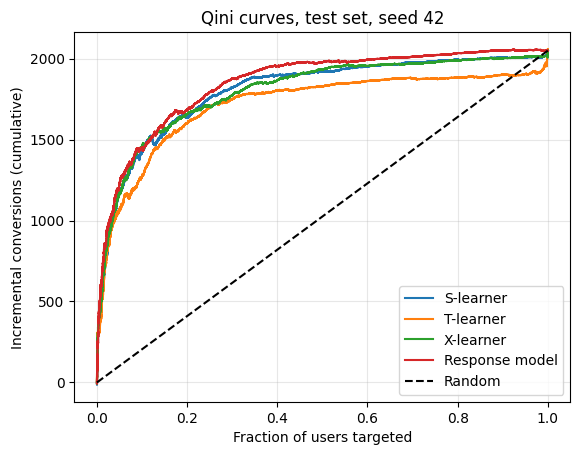

In [16]:
x = np.linspace(0, 1, len(yte))
for name in LEARNERS:
    plt.plot(x, gain_curve(yte, tte, models[(seed0, name)][1]), label=name)
plt.plot([0, 1], [0, gain_curve(yte, tte, models[(seed0, "X-learner")][1])[-1]], "k--", label="Random")
plt.xlabel("Fraction of users targeted"); plt.ylabel("Incremental conversions (cumulative)")
plt.title("Qini curves, test set, seed 42"); plt.legend(); plt.grid(alpha=0.3)
plt.savefig(f"{OUT}/qini_all_learners.png", dpi=150); plt.show()

In [17]:
s = models[(42, "X-learner")][1]
dec = pd.qcut(pd.Series(s).rank(method="first"), 10, labels=False)
rows = []
for d in range(9, -1, -1):
    m = (dec == d).to_numpy()
    rows.append({"decile (10 = highest score)": d + 1, "predicted uplift": s[m].mean(),
                 "actual uplift": yte[m][tte[m] == 1].mean() - yte[m][tte[m] == 0].mean()})
display(pd.DataFrame(rows))

,decile (10 = highest score),predicted uplift,actual uplift
0,10,0.007805,0.008047
1,9,0.000674,0.000389
2,8,0.000298,0.000180
3,7,0.000148,0.000189
4,6,0.000119,0.000253
5,5,0.000115,0.000022
6,4,0.000108,0.000067
7,3,0.000108,0.000042
8,2,0.000108,0.000084
9,1,0.000056,0.000197


In [18]:
x3 = np.mean([models[(s, "X-learner")][1] for s in MODEL_SEEDS], axis=0)
x1 = models[(42, "X-learner")][1]
print("X seed 42:        ", qini(yte, tte, x1), uplift_at(yte, tte, x1, 0.1))
print("X 3-seed ensemble:", qini(yte, tte, x3), uplift_at(yte, tte, x3, 0.1))
ci, p = paired_boot(yte, tte, x3, x1); print("ensemble minus single:", ci, f"better in {p:.0%}")

X seed 42:         0.00036879257083323143 0.008049408642060298
X 3-seed ensemble: 0.0003695803586954067 0.007970651836941341
ensemble minus single: [-9.92941883e-06  1.14077095e-05] better in 60%
